In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ── Load both files ───────────────────────────────────────────────────────────
d1 = {k: v for k, v in np.load('plots/k5_55.npz',   allow_pickle=True).items()}
d2 = {k: v for k, v in np.load('plots/k50_105.npz', allow_pickle=True).items()}

# Trim d2: remove k=50 and k=55 (already covered by d1)
k2 = d2['k_params'][:, 0]
keep2 = ~np.isin(np.round(k2, 1), [50.0, 55.0])
d2_trim = {key: val[keep2] if (np.ndim(val) > 0 and val.shape[0] == len(k2)) else val
           for key, val in d2.items()}
print(f'd1 samples: {len(d1["t"]):,}')
print(f'd2 trimmed: {keep2.sum():,} / {len(k2):,} (removed k=50,55)')

# Combine — offset d2 time so it continues after d1
t_offset = d1['t'][-1] + (d1['t'][-1] - d1['t'][-2])
combined = {}
for key in d1:
    a, b = d1[key], d2_trim[key]
    if np.ndim(a) == 0:   # scalar metadata → keep from d1
        combined[key] = a
    elif key == 't':
        combined[key] = np.concatenate([a, b + t_offset])
    else:
        combined[key] = np.concatenate([a, b], axis=0)

t      = combined['t']
k_all  = combined['k_params'][:, 0]
goal_x = combined['goal'][:, 0, 0]
force  = combined['force']

k_unique_test = sorted([kv for kv in np.unique(np.round(k_all, 1)) if kv != 200.0])
print(f'\nCombined samples: {len(t):,}')
print(f'Test k values ({len(k_unique_test)}): {k_unique_test}')

d1 samples: 442,636
d2 trimmed: 170,391 / 202,167 (removed k=50,55)

Combined samples: 613,027
Test k values (36): [np.float64(5.0), np.float64(7.0), np.float64(9.0), np.float64(11.0), np.float64(13.0), np.float64(15.0), np.float64(17.0), np.float64(19.0), np.float64(21.0), np.float64(23.0), np.float64(25.0), np.float64(27.0), np.float64(29.0), np.float64(31.0), np.float64(33.0), np.float64(35.0), np.float64(37.0), np.float64(39.0), np.float64(41.0), np.float64(43.0), np.float64(45.0), np.float64(47.0), np.float64(49.0), np.float64(51.0), np.float64(53.0), np.float64(55.0), np.float64(60.0), np.float64(65.0), np.float64(70.0), np.float64(75.0), np.float64(80.0), np.float64(85.0), np.float64(90.0), np.float64(95.0), np.float64(100.0), np.float64(105.0)]


In [2]:
# ── Extract MOVING_OUT intervals for each k ───────────────────────────────────
# Strategy: within each contiguous segment at k=test_k,
# the ref goes 0→-25cm (MOVING_OUT) then -25cm→0 (MOVING_BACK).
# Split at the minimum of goal_x to isolate only the outward sweep.

segments = {}   # k_value → list of (goal_x_out, force_out) arrays

k_rounded = np.round(k_all, 1)

for kv in k_unique_test:
    in_seg = k_rounded == kv
    # find contiguous blocks
    changes = np.diff(in_seg.astype(int))
    starts  = np.where(changes == 1)[0] + 1
    ends    = np.where(changes == -1)[0] + 1
    if in_seg[0]:  starts = np.concatenate([[0], starts])
    if in_seg[-1]: ends   = np.concatenate([ends, [len(in_seg)]])

    segs_kv = []
    for s, e in zip(starts, ends):
        gx = goal_x[s:e]
        f  = force[s:e]
        if len(gx) < 5:
            continue
        # find where goal_x is minimum (end of outward sweep)
        split = int(np.argmin(gx))
        if split < 3:   # degenerate segment, skip
            continue
        # keep only the outward portion (0 → -25cm)
        segs_kv.append((gx[:split+1], f[:split+1]))
    segments[kv] = segs_kv

valid_k = [kv for kv in k_unique_test if segments[kv]]
print(f'Extracted segments for {len(valid_k)} k values')
for kv in valid_k:
    print(f'  k={kv:.0f}: {len(segments[kv])} sweep(s)')

Extracted segments for 36 k values
  k=5: 1 sweep(s)
  k=7: 1 sweep(s)
  k=9: 1 sweep(s)
  k=11: 1 sweep(s)
  k=13: 1 sweep(s)
  k=15: 1 sweep(s)
  k=17: 1 sweep(s)
  k=19: 1 sweep(s)
  k=21: 1 sweep(s)
  k=23: 1 sweep(s)
  k=25: 1 sweep(s)
  k=27: 1 sweep(s)
  k=29: 1 sweep(s)
  k=31: 1 sweep(s)
  k=33: 1 sweep(s)
  k=35: 1 sweep(s)
  k=37: 1 sweep(s)
  k=39: 1 sweep(s)
  k=41: 1 sweep(s)
  k=43: 1 sweep(s)
  k=45: 1 sweep(s)
  k=47: 1 sweep(s)
  k=49: 1 sweep(s)
  k=51: 1 sweep(s)
  k=53: 1 sweep(s)
  k=55: 1 sweep(s)
  k=60: 1 sweep(s)
  k=65: 1 sweep(s)
  k=70: 1 sweep(s)
  k=75: 1 sweep(s)
  k=80: 1 sweep(s)
  k=85: 1 sweep(s)
  k=90: 1 sweep(s)
  k=95: 1 sweep(s)
  k=100: 1 sweep(s)
  k=105: 1 sweep(s)


/tmp/ipykernel_8134/3159851677.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('coolwarm')


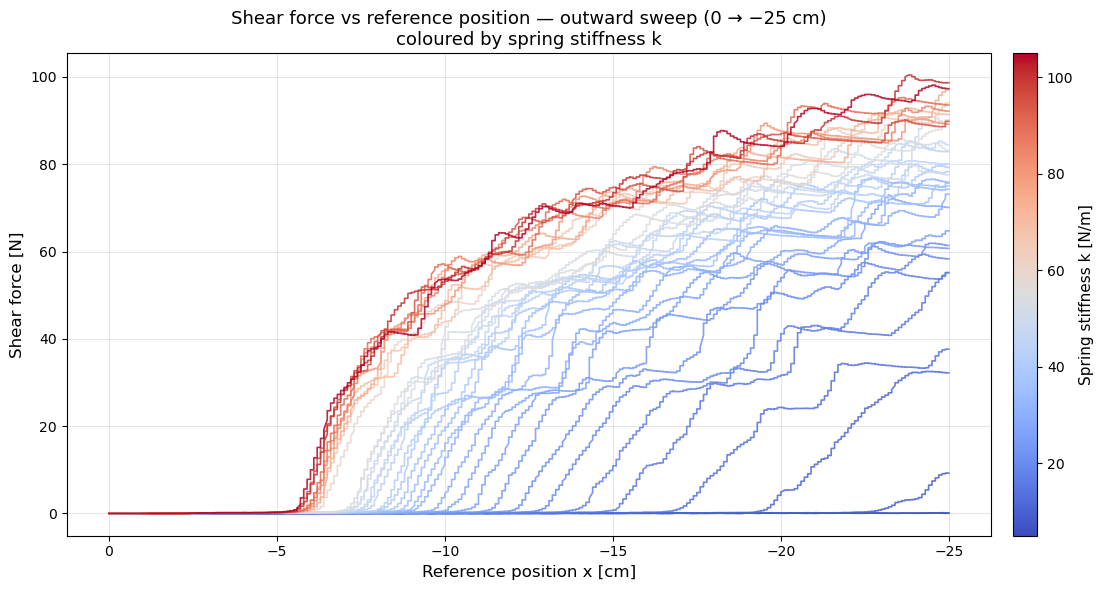

[OK] Saved → plots/force_vs_pos_by_k.png


In [3]:
# ── Plot: shear force vs ref position, coloured by k ─────────────────────────
# Colormap: cold (blue) for low k → hot (red) for high k

norm   = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap   = cm.get_cmap('coolwarm')

fig, ax = plt.subplots(figsize=(12, 6))

for kv in valid_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        label = f'k={kv:.0f}' if idx == 0 else None
        ax.plot(gx * 100, f, color=color, linewidth=1.2,
                alpha=0.85, label=label)

# Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness k [N/m]', fontsize=11)

ax.set_xlabel('Reference position x [cm]', fontsize=12)
ax.set_ylabel('Shear force [N]', fontsize=12)
ax.set_title('Shear force vs reference position — outward sweep (0 → −25 cm)\n'
             'coloured by spring stiffness k', fontsize=13)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()   # 0 on left, -25 on right

plt.tight_layout()
plt.savefig('plots/force_vs_pos_by_k.png', dpi=200, bbox_inches='tight')
plt.show()
print('[OK] Saved → plots/force_vs_pos_by_k.png')

In [ ]:
# ── Plot: F/x vs x (apparent stiffness) coloured by k ────────────────────────
# Skip points where |x| < X_MIN_CM to avoid division-by-zero near origin
X_MIN_CM = 0.5   # [cm]  ignore first 0.5 cm

norm = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap = cm.get_cmap('coolwarm')

fig, ax = plt.subplots(figsize=(12, 6))

for kv in valid_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        x_cm = gx * 100          # convert to cm
        mask = np.abs(x_cm) >= X_MIN_CM
        xm, fm = x_cm[mask], f[mask]
        if len(xm) < 2:
            continue
        ratio = fm / xm           # F/x  [N/cm]
        label = f'k={kv:.0f}' if idx == 0 else None
        ax.plot(xm, ratio, color=color, linewidth=1.2, alpha=0.85, label=label)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness k [N/m]', fontsize=11)

ax.set_xlabel('Reference position x [cm]', fontsize=12)
ax.set_ylabel('F / x  [N/cm]', fontsize=12)
ax.set_title('Apparent stiffness F/x vs displacement — outward sweep (0 → −25 cm)
'
             'coloured by spring stiffness k', fontsize=13)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()

plt.tight_layout()
plt.savefig('plots/stiffness_vs_pos_by_k.png', dpi=200, bbox_inches='tight')
plt.show()
print('[OK] Saved → plots/stiffness_vs_pos_by_k.png')